In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataset_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25'

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

# Define the input size for ResNeXt-50
IMG_SIZE = (224, 224)
BATCH_SIZE = 512

# Data augmentation and preprocessing
datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,  # Use ResNet's preprocessing
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    validation_split=0.1
)

# Load training data
train_generator = datagen.flow_from_directory(
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
)

# Load validation data
validation_generator = datagen.flow_from_directory(
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
)
# Load and preprocess test images
test_generator = datagen.flow_from_directory(
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Test',  # Path to the test dataset
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

Found 5837 images belonging to 7 classes.
Found 646 images belonging to 7 classes.
Found 717 images belonging to 7 classes.


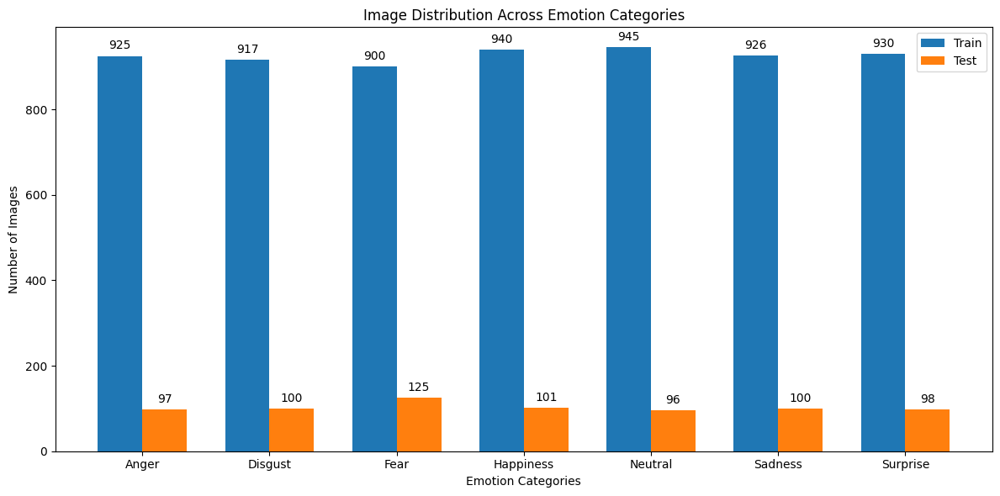

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd

# Define your data paths
train_data_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train'
test_data_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Test'

# Define your emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Initialize counts for each category
train_counts = {emotion: 0 for emotion in emotion_categories}
test_counts = {emotion: 0 for emotion in emotion_categories}

# Count images in train dataset
for emotion in emotion_categories:
    emotion_path = os.path.join(train_data_path, emotion)
    train_counts[emotion] = len(os.listdir(emotion_path))

# Count images in test dataset
for emotion in emotion_categories:
    emotion_path = os.path.join(test_data_path, emotion)
    test_counts[emotion] = len(os.listdir(emotion_path))

df = pd.DataFrame({
    'Emotion': emotion_categories,
    'Train Count': list(train_counts.values()),
    'Test Count': list(test_counts.values())
})

# Get the positions for the bars
x = np.arange(len(emotion_categories))
width = 0.35  # Width of the bars

# Create the bar plot
fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, df['Train Count'], width, label='Train')
rects2 = ax.bar(x + width/2, df['Test Count'], width, label='Test')

# Add labels, title, and legend
ax.set_xlabel('Emotion Categories')
ax.set_ylabel('Number of Images')
ax.set_title('Image Distribution Across Emotion Categories')
ax.set_xticks(x)
ax.set_xticklabels(emotion_categories)
ax.legend()

# Add count labels using the provided code snippet
for index, row in df.iterrows():
    plt.text(x=index - width/2, y=row['Train Count'] + 10, s=str(row['Train Count']), ha='center', va='bottom', fontsize=10)
    plt.text(x=index + width/2, y=row['Test Count'] + 10, s=str(row['Test Count']), ha='center', va='bottom', fontsize=10)

# Display the plot
plt.tight_layout()
plt.show()

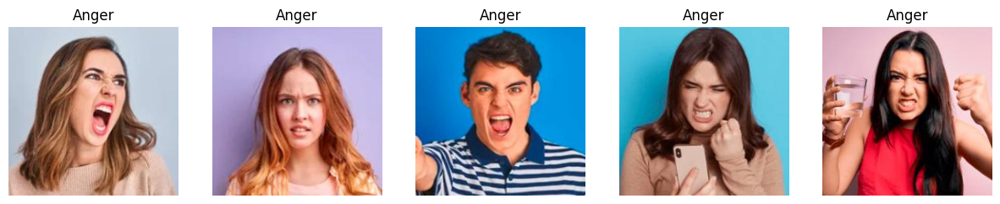

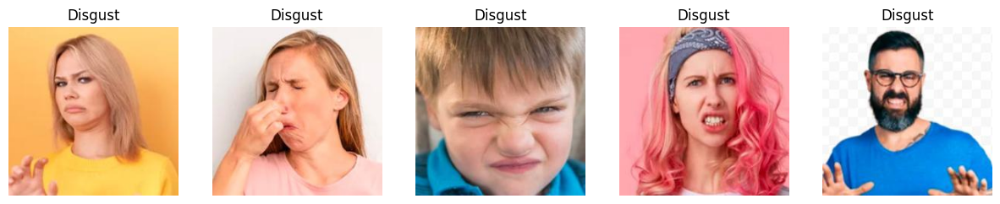

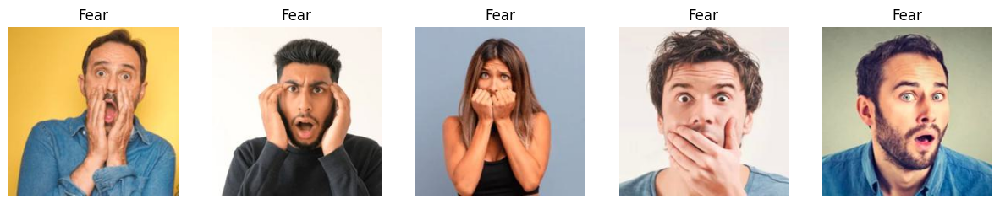

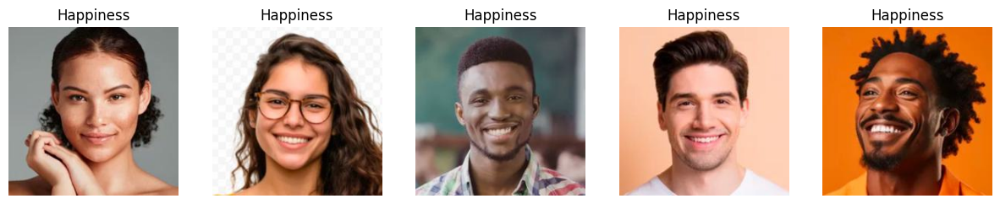

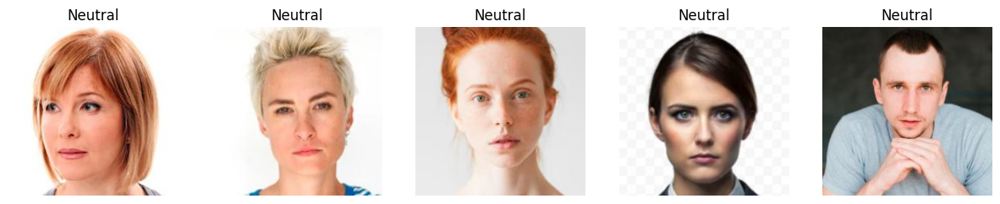

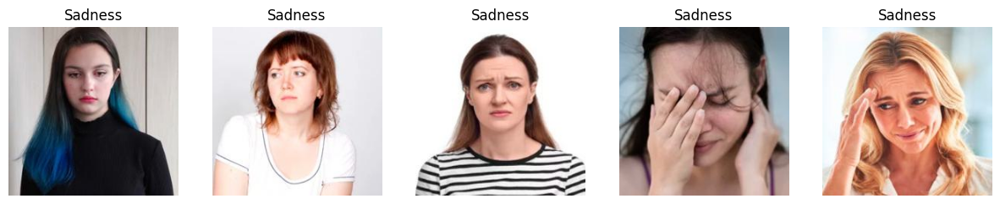

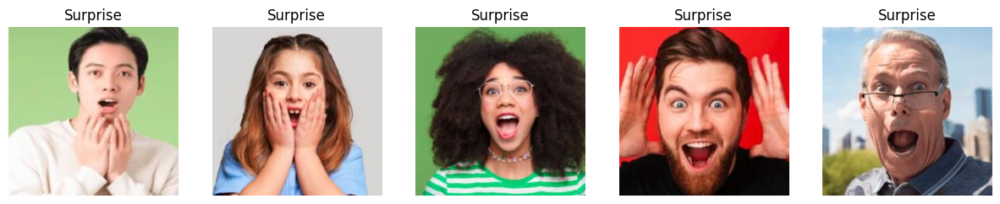

In [ ]:
import matplotlib.pyplot as plt
import os
from PIL import Image
import random

def plot_sample_images(img_paths, labels, num_images=5):
    fig, axes = plt.subplots(1, num_images, figsize=(15, 5))
    for i, img_path in enumerate(img_paths[:num_images]):
        img = Image.open(img_path)
        axes[i].imshow(img, cmap='gray')
        axes[i].set_title(labels[i])
        axes[i].axis('off')
    plt.show()

# Define your data paths and emotion categories
data_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train'
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']
for emotion in emotion_categories:
    emotion_path = os.path.join(data_path, emotion)
    all_img_files = os.listdir(emotion_path)
    random_img_files = random.sample(all_img_files, 5)
    img_paths = [os.path.join(emotion_path, img_file) for img_file in random_img_files]
    plot_sample_images(img_paths, [emotion] * len(img_paths))

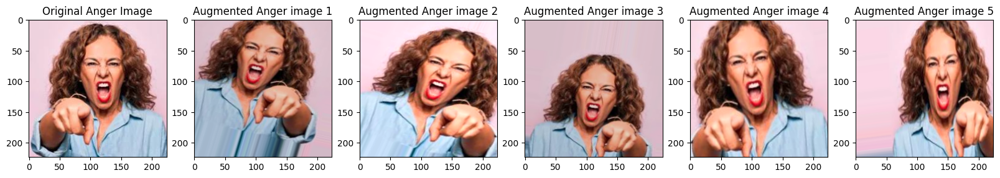

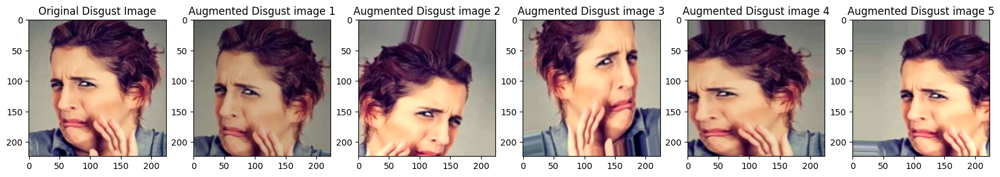

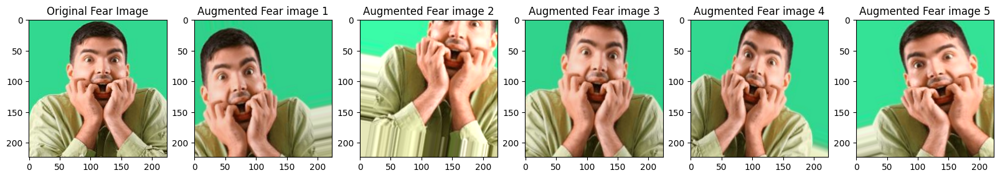

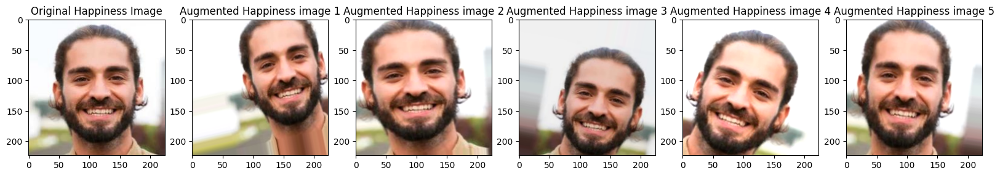

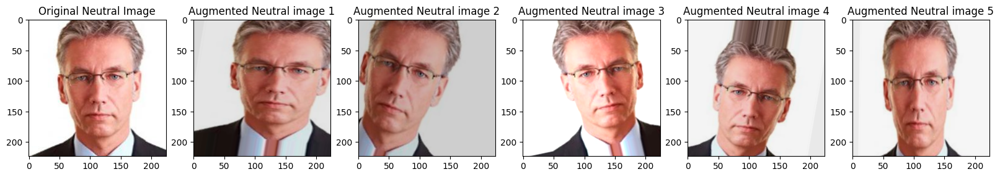

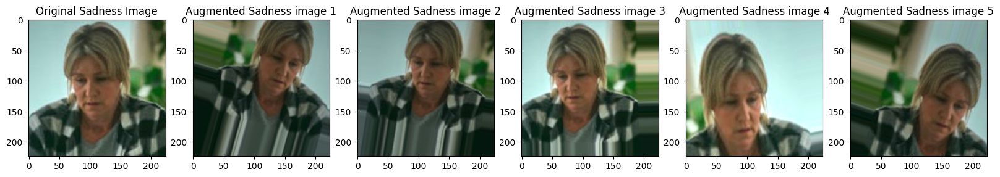

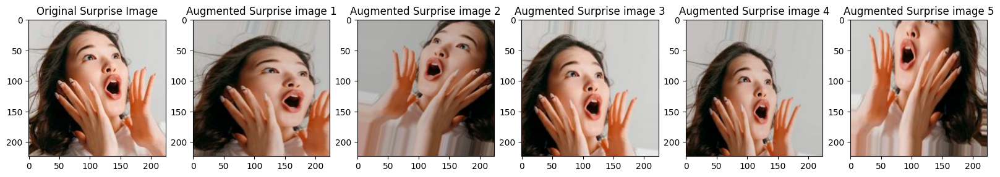

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import os

# Define data augmentation
datagen = ImageDataGenerator(
    rescale=1.0/255,  # Normalize pixel values to [0, 1]
    rotation_range=20,  # Add rotation
    width_shift_range=0.2,  # Add width shift
    height_shift_range=0.2, # Add height shift
    brightness_range=[0.8, 1.2], # Add brightness adjustmen
    shear_range=0.2,  # Apply shearing for data augmentation
    zoom_range=0.2,   # Randomly zoom into images
    horizontal_flip=True,  # Randomly flip images horizontally
    fill_mode='nearest'
)

# Define your data paths and emotion categories
data_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train'  # Replace with your actual path
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Loop through each emotion category and plot sample images
for emotion in emotion_categories:
    emotion_path = os.path.join(data_path, emotion)
    # Get one sample image from each category
    img_path = os.path.join(emotion_path, os.listdir(emotion_path)[0])

    # Load a single image and apply augmentation
    img = Image.open(img_path).resize((224, 224))
    # Convert the image to RGB if it's not already
    img = img.convert('RGB')
    img = np.array(img)
    img = img.reshape((1, 224, 224, 3))

    # Use __next__() instead of next() and get the first item from the batch
    augmented_imgs = [datagen.flow(img, batch_size=1).__next__()[0] for _ in range(5)]

    fig, axes = plt.subplots(1, 6, figsize=(20, 5))
    axes[0].imshow(img[0].astype('uint8'))  # Original image
    axes[0].set_title(f"Original {emotion} Image")

    for i, aug_img in enumerate(augmented_imgs):
        # Rescale augmented image to 0-255 and convert to uint8
        aug_img = (aug_img * 255).astype('uint8')
        axes[i + 1].imshow(aug_img)
        axes[i + 1].set_title(f"Augmented {emotion} image {i+1}")

    plt.show()

In [ ]:
import random
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Define data augmentation
datagen = ImageDataGenerator(
    rescale=1.0/255,  # Normalize pixel values to [0, 1]
    rotation_range=20,  # Add rotation
    width_shift_range=0.2,  # Add width shift
    height_shift_range=0.2, # Add height shift
    brightness_range=[0.8, 1.2], # Add brightness adjustment
    shear_range=0.2,  # Apply shearing for data augmentation
    zoom_range=0.2,   # Randomly zoom into images
    horizontal_flip=True,  # Randomly flip images horizontally
    fill_mode='nearest'
)

# Set random seed (you can change this to any integer)
random_state = 25

# Loop through each emotion category
for emotion in emotion_categories:
    print(f"Processing emotion: {emotion}")
    emotion_path = os.path.join('/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train', emotion)

    # Get a list of all image files in the emotion directory
    all_img_files = os.listdir(emotion_path)

    # Randomly select 3 image files
    random.seed(random_state)  # Set random seed for reproducibility
    selected_img_files = random.sample(all_img_files, 3)

    # Loop through 3 random images for each emotion
    for img_file in selected_img_files:
        img_path = os.path.join(emotion_path, img_file)
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)

        # Apply augmentation
        augmented_imgs = [datagen.flow(x, batch_size=1).__next__()[0] for _ in range(5)]

        fig, axes = plt.subplots(1, 6, figsize=(20, 5))
        axes[0].imshow(img)  # Original image
        axes[0].set_title(f"Original {emotion} Image")
        axes[0].axis('off')  # Turn off axis for the original image

        for i, aug_img in enumerate(augmented_imgs):
            # Rescale augmented image to 0-255 and convert to uint8
            aug_img = (aug_img * 255).astype('uint8')
            axes[i + 1].imshow(aug_img)
            axes[i + 1].set_title(f"Augmented {emotion} image {i+1}")
            axes[i + 1].axis('off')  # Turn off axis for the augmented images

        plt.tight_layout()
        plt.show()

In [ ]:
from tensorflow.keras.applications import ResNet101V2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.optimizers import Adam

# Create Precision and Recall metrics outside the function
precision_metric = Precision()
recall_metric = Recall()

# Custom F1-score metric
def f1_score(y_true, y_pred):
    precision = precision_metric(y_true, y_pred)  # Use pre-created metric
    recall = recall_metric(y_true, y_pred)      # Use pre-created metric
    f1 = 2 * ((precision * recall) / (precision + recall + tf.keras.backend.epsilon()))
    return f1

# Apply mixed precision for faster training and less GPU load
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

# Load pre-trained ResNet101V2 model without the top classification layer
base_model = ResNet101V2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Freeze the base model to retain pre-trained weights
base_model.trainable = False

# Add custom classification layers
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
# Apply the output layer to the previous layer's output
output = Dense(7, activation='softmax')(x)  # 7 classes: anger, disgust, fear, happiness, neutral, sadness and surprise

# Create the final model
model = Model(inputs=base_model.input, outputs=output)

171317808/171317808 ━━━━━━━━━━━━━━━━━━━━ 11s 0us/step


In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 56, 56,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 56, 56,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 58, 58,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_pre… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 56, 56,    │          0 │ conv2_block1_0_c

 Total params: 43,679,239 (166.62 MB)

 Trainable params: 1,052,679 (4.02 MB)

 Non-trainable params: 42,626,560 (162.61 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy', Precision(name='precision'), Recall(name='recall'), f1_score]
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=30,
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    validation_steps=validation_generator.samples // BATCH_SIZE
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 3148s 286s/step - accuracy: 0.1487 - f1_score: 0.1480 - loss: 13.6617 - precision: 0.1488 - recall: 0.1487 - val_accuracy: 0.1445 - val_f1_score: 0.1484 - val_loss: 13.7885 - val_precision: 0.1445 - val_recall: 0.1445
Epoch 2/30
 1/11 ━━━━━━━━━━━━━━━━━━━━ 1s 146ms/step - accuracy: 0.1465 - f1_score: 0.1482 - loss: 13.7134 - precision: 0.1465 - recall: 0.1465

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 596ms/step - accuracy: 0.1465 - f1_score: 0.1482 - loss: 13.7134 - precision: 0.1465 - recall: 0.1465 - val_accuracy: 0.1465 - val_f1_score: 0.1481 - val_loss: 13.7570 - val_precision: 0.1465 - val_recall: 0.1465
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 66s 6s/step - accuracy: 0.1423 - f1_score: 0.1450 - loss: 13.8193 - precision: 0.1423 - recall: 0.1423 - val_accuracy: 0.1465 - val_f1_score: 0.1456 - val_loss: 13.7570 - val_precision: 0.1465 - val_recall: 0.1465
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 713ms/step - accuracy: 0.1465 - f1_score: 0.1457 - loss: 13.7570 - precision: 0.1465 - recall: 0.1465 - val_accuracy: 0.1406 - val_f1_score: 0.1455 - val_loss: 13.8515 - val_precision: 0.1406 - val_recall: 0.1406
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 68s 6s/step - accuracy: 0.1416 - f1_score: 0.1450 - loss: 13.8358 - precision: 0.1416 - recall: 0.1416 - val_accuracy: 0.1426 - val_f1_score: 0.1443 - val_loss: 13.8200 - val_precision: 0.1426 - val_recall: 0.1426

In [ ]:
# Evaluate the model and unpack the returned values appropriately
test_loss, test_accuracy, test_precision, test_recall, test_f1_score = model.evaluate(validation_generator)

# Print the test accuracy
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 17s 11s/step - accuracy: 0.1424 - f1_score: 0.1431 - loss: 13.8226 - precision: 0.1424 - recall: 0.1424
Test Accuracy: 14.24%


In [ ]:
# Unfreeze the base model for fine-tuning
base_model.trainable = True

# Use a lower learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy', Precision(name='precision'), Recall(name='recall'), f1_score]
)

# Fine-tune the model
fine_tune_history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=30,  # Add more epochs for fine-tuning
    steps_per_epoch=train_generator.samples // BATCH_SIZE,
    validation_steps=validation_generator.samples // BATCH_SIZE
)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 292s 14s/step - accuracy: 0.1418 - f1_score: 0.1430 - loss: 6.6190 - precision: 0.1417 - recall: 0.1416 - val_accuracy: 0.1426 - val_f1_score: 0.1431 - val_loss: 13.7985 - val_precision: 0.1426 - val_recall: 0.1426
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 602ms/step - accuracy: 0.1523 - f1_score: 0.1431 - loss: 6.5964 - precision: 0.1526 - recall: 0.1523 - val_accuracy: 0.1484 - val_f1_score: 0.1431 - val_loss: 13.6723 - val_precision: 0.1484 - val_recall: 0.1484
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 67s 6s/step - accuracy: 0.2315 - f1_score: 0.1418 - loss: 2.3314 - precision: 0.1260 - recall: 0.0238 - val_accuracy: 0.1445 - val_f1_score: 0.1402 - val_loss: 6.2181 - val_precision: 0.1327 - val_recall: 0.1016
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 711ms/step - accuracy: 0.3633 - f1_score: 0.1398 - loss: 1.7871 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.1758 - val_f1_score: 0.1398 - val_loss: 5.5031 - val_precision: 0.1499 - val

In [ ]:
# Evaluate the model and unpack the returned values appropriately
test_loss, test_accuracy, test_precision, test_recall, test_f1_score = model.evaluate(validation_generator)

# Print the test accuracy
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 12s 6s/step - accuracy: 0.8173 - f1_score: 0.4272 - loss: 0.8709 - precision: 0.8200 - recall: 0.8111
Test Accuracy: 81.73%


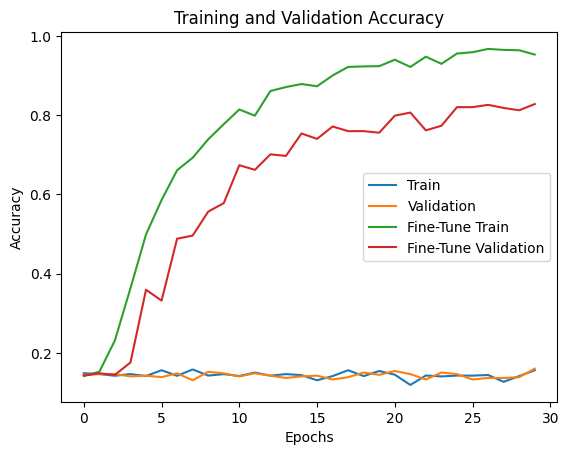

In [ ]:
# Plot training & validation accuracy
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.plot(fine_tune_history.history['accuracy'], label='Fine-Tune Train')
plt.plot(fine_tune_history.history['val_accuracy'], label='Fine-Tune Validation')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Training and Validation Accuracy')
plt.show()

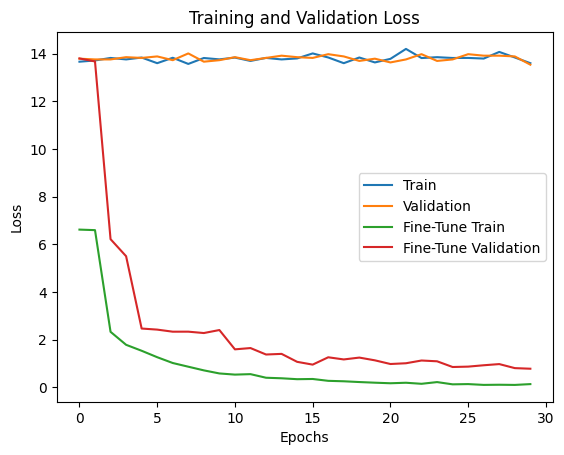

In [ ]:
# Plot training & validation loss
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.plot(fine_tune_history.history['loss'], label='Fine-Tune Train')
plt.plot(fine_tune_history.history['val_loss'], label='Fine-Tune Validation')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Validation Loss')
plt.show()

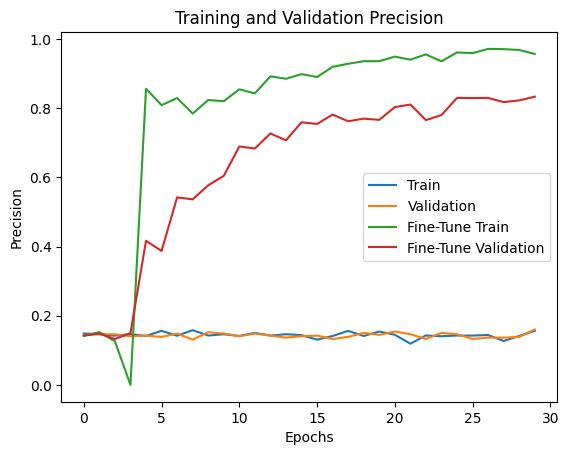

In [ ]:
# Plot training & validation precision
plt.plot(history.history['precision'], label='Train')
plt.plot(history.history['val_precision'], label='Validation')
plt.plot(fine_tune_history.history['precision'], label='Fine-Tune Train')
plt.plot(fine_tune_history.history['val_precision'], label='Fine-Tune Validation')
plt.xlabel('Epochs')
plt.ylabel('Precision')
plt.legend()
plt.title('Training and Validation Precision')
plt.show()

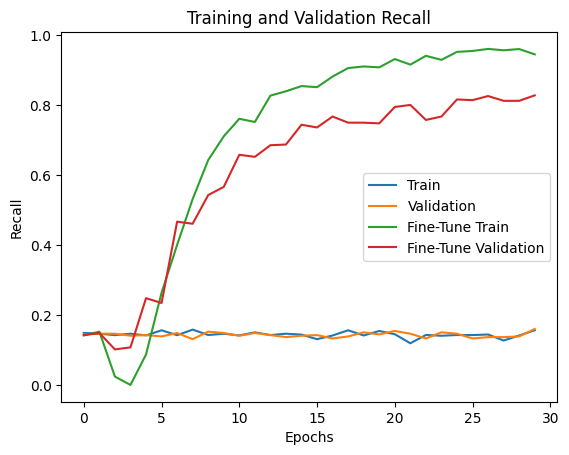

In [ ]:
# Plot training & validation recall
plt.plot(history.history['recall'], label='Train')
plt.plot(history.history['val_recall'], label='Validation')
plt.plot(fine_tune_history.history['recall'], label='Fine-Tune Train')
plt.plot(fine_tune_history.history['val_recall'], label='Fine-Tune Validation')
plt.xlabel('Epochs')
plt.ylabel('Recall')
plt.legend()
plt.title('Training and Validation Recall')
plt.show()

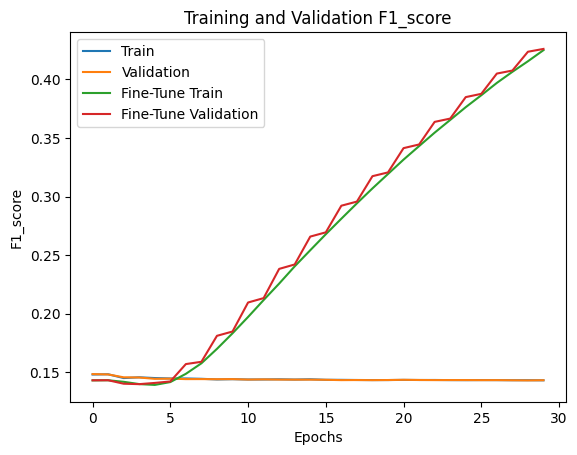

In [ ]:
# Plot training & validation f1_score
plt.plot(history.history['f1_score'], label='Train')
plt.plot(history.history['val_f1_score'], label='Validation')
plt.plot(fine_tune_history.history['f1_score'], label='Fine-Tune Train')
plt.plot(fine_tune_history.history['val_f1_score'], label='Fine-Tune Validation')
plt.xlabel('Epochs')
plt.ylabel('F1_score')
plt.legend()
plt.title('Training and Validation F1_score')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━

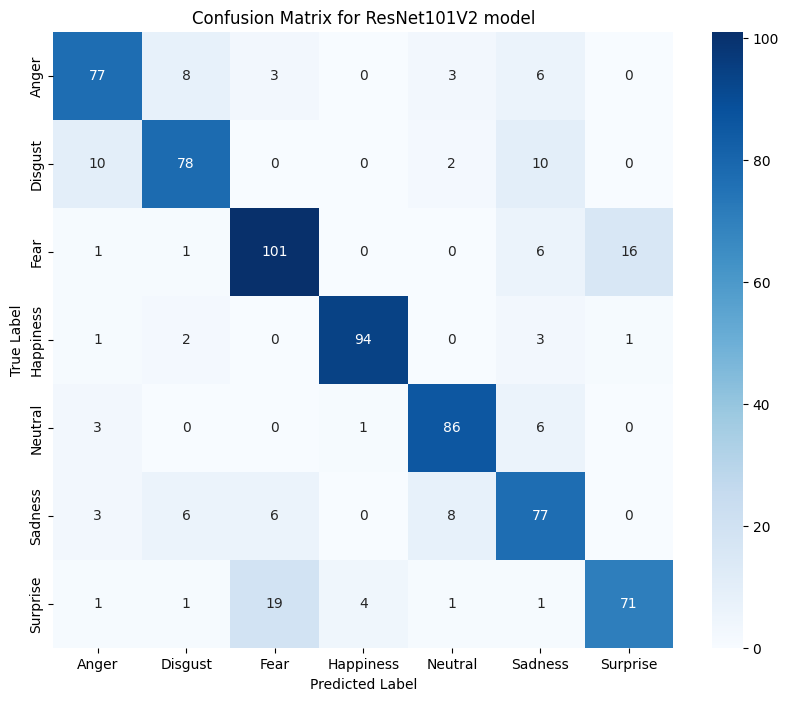

In [ ]:
import numpy as np
import os
from tensorflow.keras.preprocessing import image
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Define your emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Initialize empty lists to store all predicted and true emotions
all_predicted_emotions = []
all_true_emotions = []

# Loop through each emotion category
for emotion in emotion_categories:
    # Define the path to the emotion folder
    emotion_folder_path = os.path.join('/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Test', emotion)

    # Get a list of all image files in the emotion folder
    image_files = [f for f in os.listdir(emotion_folder_path) if os.path.isfile(os.path.join(emotion_folder_path, f))]

    # Loop through each image file and make a prediction
    for image_file in image_files:
        # Construct the full path to the image
        img_path = os.path.join(emotion_folder_path, image_file)

        # Load and preprocess the image
        img = image.load_img(img_path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)

        # Make the prediction
        prediction = model.predict(img_array)

        # Get the predicted class index and emotion label
        predicted_class_index = np.argmax(prediction)
        predicted_emotion = emotion_categories[predicted_class_index]

        # Append the predicted and true emotions to the lists
        all_predicted_emotions.append(predicted_emotion)
        all_true_emotions.append(emotion)  # True emotion is the current emotion category

# Convert the lists to NumPy arrays
all_predicted_emotions = np.array(all_predicted_emotions)
all_true_emotions = np.array(all_true_emotions)

# Create the confusion matrix
cm_all_emotions = confusion_matrix(all_true_emotions, all_predicted_emotions, labels=emotion_categories)

# Plot the confusion matrix using Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm_all_emotions, annot=True, fmt="d", cmap="Blues",
            xticklabels=emotion_categories, yticklabels=emotion_categories)
plt.title("Confusion Matrix for ResNet101V2 model")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

In [ ]:
import numpy as np
import os
from tensorflow.keras.preprocessing import image
from sklearn.metrics import confusion_matrix
from tensorflow.keras.applications.efficientnet import preprocess_input

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Path to your Test folder
test_folder_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Test'

true_labels = []
predicted_labels = []

# Loop through each emotion category folder in the Test folder
for emotion_index, emotion in enumerate(emotion_categories):
    emotion_folder_path = os.path.join(test_folder_path, emotion)

    # Loop through images in the emotion folder
    for image_file in os.listdir(emotion_folder_path):
        img_path = os.path.join(emotion_folder_path, image_file)
        img = image.load_img(img_path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)

        # Make prediction
        prediction = model.predict(img_array)
        predicted_class_index = np.argmax(prediction)

        # Append labels
        true_labels.append(emotion_index)  # Use emotion_index for true label
        predicted_labels.append(predicted_class_index)

# Calculate confusion matrix
cm = confusion_matrix(true_labels, predicted_labels, labels=range(len(emotion_categories)))

# Print TP, FP, TN, FN for each emotion
for emotion_index, emotion in enumerate(emotion_categories):
    TP = cm[emotion_index, emotion_index]
    FP = sum(cm[i, emotion_index] for i in range(len(emotion_categories)) if i != emotion_index)
    FN = sum(cm[emotion_index, i] for i in range(len(emotion_categories)) if i != emotion_index)
    TN = sum(cm[i, j] for i in range(len(emotion_categories)) for j in range(len(emotion_categories)) if i != emotion_index and j != emotion_index)

    print(f"For {emotion} Emotion:")
    print("True Positives (TP):", TP)
    print("False Positives (FP):", FP)
    print("True Negatives (TN):", TN)
    print("False Negatives (FN):", FN)
    print("-" * 20)  # Separator between emotions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━

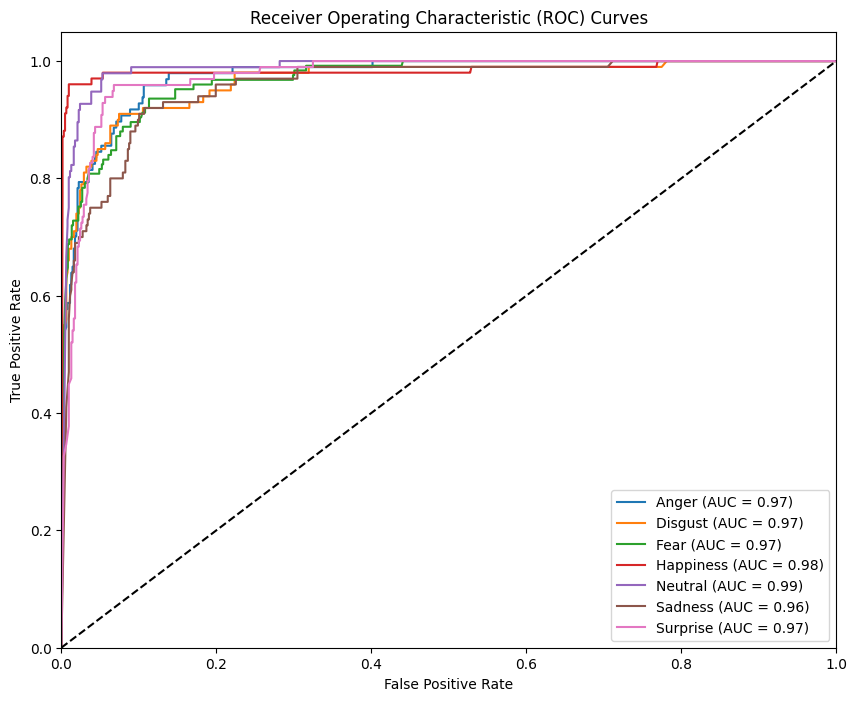

In [ ]:
import numpy as np
import os
from tensorflow.keras.preprocessing import image
from sklearn.metrics import roc_curve, auc
from tensorflow.keras.applications.efficientnet import preprocess_input
import matplotlib.pyplot as plt

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Path to your Test folder
test_folder_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Test'

# Initialize lists to store true and predicted probabilities for each class
true_labels = []
predicted_probabilities = []

# Loop through each emotion category folder in the Test folder
for emotion_index, emotion in enumerate(emotion_categories):
    emotion_folder_path = os.path.join(test_folder_path, emotion)

    # Loop through images in the emotion folder
    for image_file in os.listdir(emotion_folder_path):
        img_path = os.path.join(emotion_folder_path, image_file)
        img = image.load_img(img_path, target_size=(224, 224))
        img_array = image.img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)
        img_array = preprocess_input(img_array)

        # Make prediction (get probabilities)
        prediction = model.predict(img_array)[0]  # Get probabilities for all classes

        # Append true label (one-hot encoded) and predicted probabilities
        true_label = np.zeros(len(emotion_categories))
        true_label[emotion_index] = 1  # One-hot encoding
        true_labels.append(true_label)
        predicted_probabilities.append(prediction)

# Convert lists to NumPy arrays
true_labels = np.array(true_labels)
predicted_probabilities = np.array(predicted_probabilities)

# Plot ROC curves for each class
plt.figure(figsize=(10, 8))
for i in range(len(emotion_categories)):
    fpr, tpr, _ = roc_curve(true_labels[:, i], predicted_probabilities[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{emotion_categories[i]} (AUC = {roc_auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line for random classifier
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.show()

In [ ]:
model.save('/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25_ResNet101V2.h5')

In [ ]:
!pip install tf-keras-vis

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.5/52.5 kB 5.7 MB/s eta 0:00:00


In [ ]:
from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam = Gradcam(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam

# Loop through each emotion category
for emotion in emotion_categories:
    print(f"Processing emotion: {emotion}")  # Print current emotion
    emotion_path = os.path.join('/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Test', emotion)
    img_paths = [os.path.join(emotion_path, img_name) for img_name in os.listdir(emotion_path)[:3]]

    # Loop through 3 images for each emotion
    for i, img_path in enumerate(img_paths):
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)

        heatmap = grad_cam_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

In [ ]:
from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam = Gradcam(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam

# Loop through each emotion category
for emotion in emotion_categories:
    print(f"Processing emotion: {emotion}")  # Print current emotion
    emotion_path = os.path.join('/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train', emotion)
    img_paths = [os.path.join(emotion_path, img_name) for img_name in os.listdir(emotion_path)[:3]]

    # Loop through 3 images for each emotion
    for i, img_path in enumerate(img_paths):
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)

        heatmap = grad_cam_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

gradCAM prediction for a single image

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


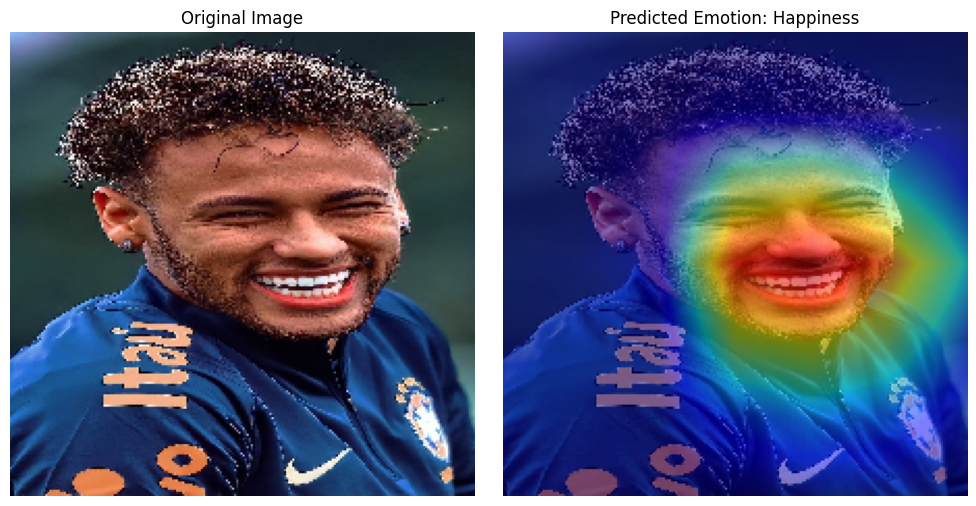

In [ ]:
from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam = Gradcam(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam

# Load and preprocess the image
img_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/neymar.jpg'
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)

# Generate heatmap
heatmap = grad_cam_heatmap(model, x)
heatmap = np.uint8(255 * heatmap[0])

# Display the original and heatmap overlaid images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Original Image
axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis('off')

# Heatmap Overlay
axes[1].imshow(img)
axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
axes[1].set_title(f"Predicted Emotion: {emotion_categories[np.argmax(model.predict(x))]}")
axes[1].axis('off')

plt.tight_layout()
plt.show()

gradCAM prediction for 3 images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


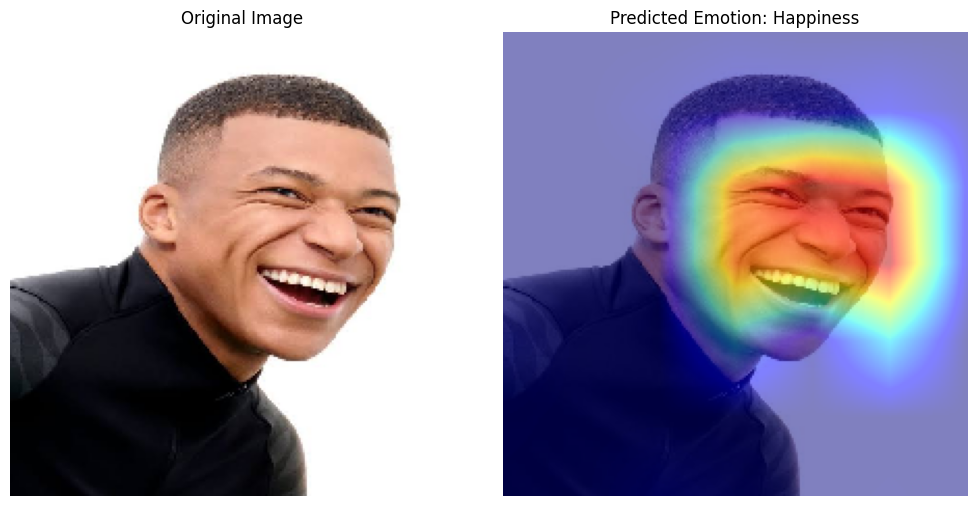

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


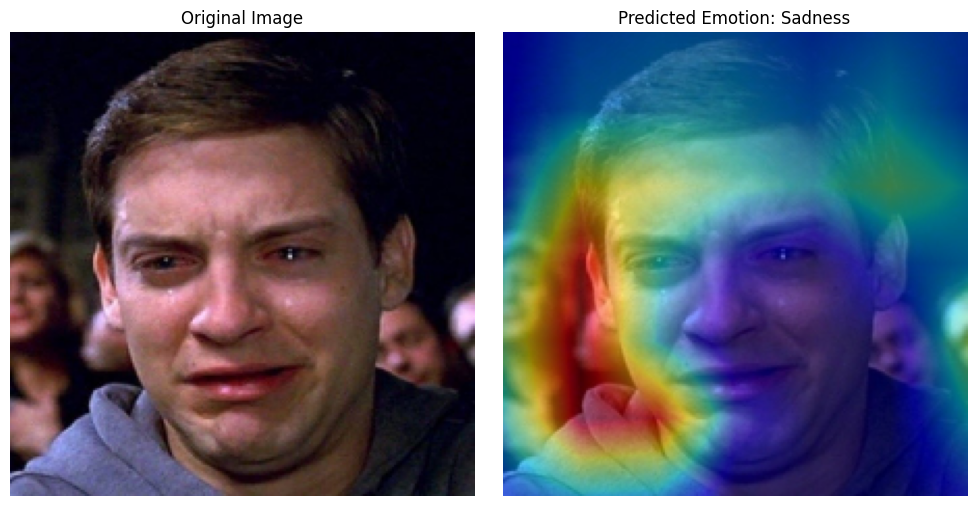

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


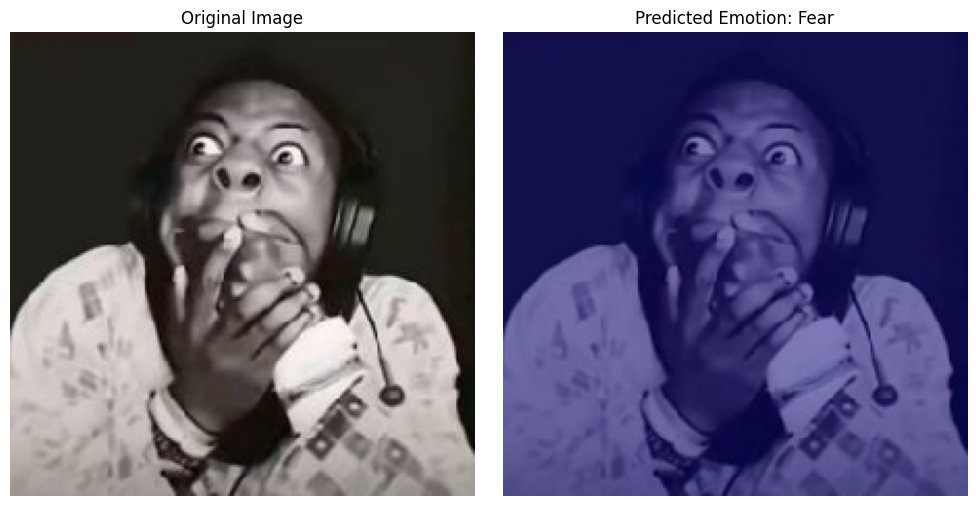

In [ ]:
from tf_keras_vis.gradcam import Gradcam
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam = Gradcam(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam

# Load and preprocess 3 images
img_paths = [
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/mbappe.jpg',
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/tobey.jpg',
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/speed.jpg'
]

# Process each image
for img_path in img_paths:
    img = image.load_img(img_path, target_size=(224, 224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)  # Assuming you have preprocess_input defined

    heatmap = grad_cam_heatmap(model, x)
    heatmap = np.uint8(255 * heatmap[0])

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(img)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(img)
    axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
    predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
    axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


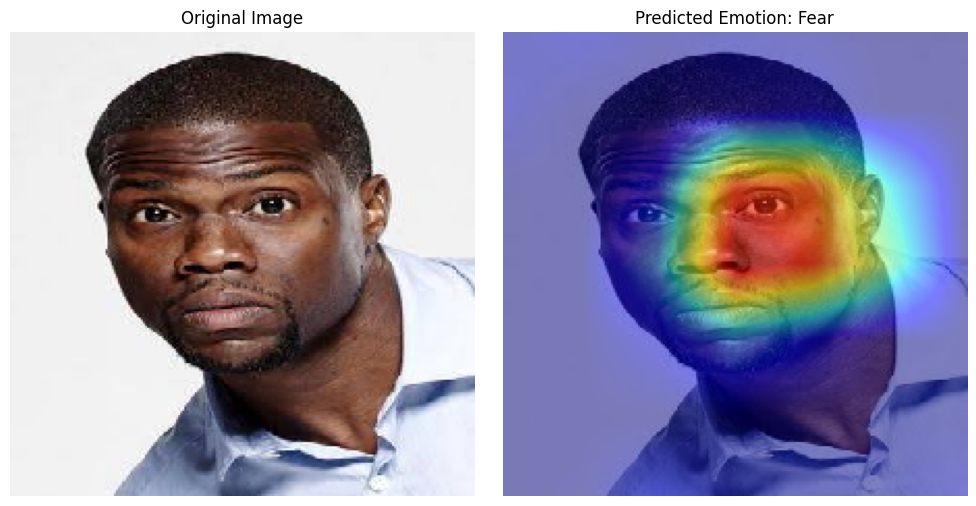

In [ ]:
from tf_keras_vis.gradcam import Gradcam  # Import GradCAM
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam = Gradcam(model, clone=False)  # Initialize GradCAM

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam(loss, image, penultimate_layer=layer_name)  # Get heatmap
    cam = normalize(cam)
    return cam

# Specify the folder containing images
image_folder = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/celeb'  # Replace with your folder path

# Loop through each image in the folder
for filename in os.listdir(image_folder):
    if filename.endswith(('.jpg', '.jpeg', '.png')):  # Check for image file extensions
        img_path = os.path.join(image_folder, filename)

        # Load and preprocess the image
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)  # Assuming you have preprocess_input defined

        # Generate heatmap using GradCAM
        heatmap = grad_cam_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        # Display the original and heatmap overlaid images
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


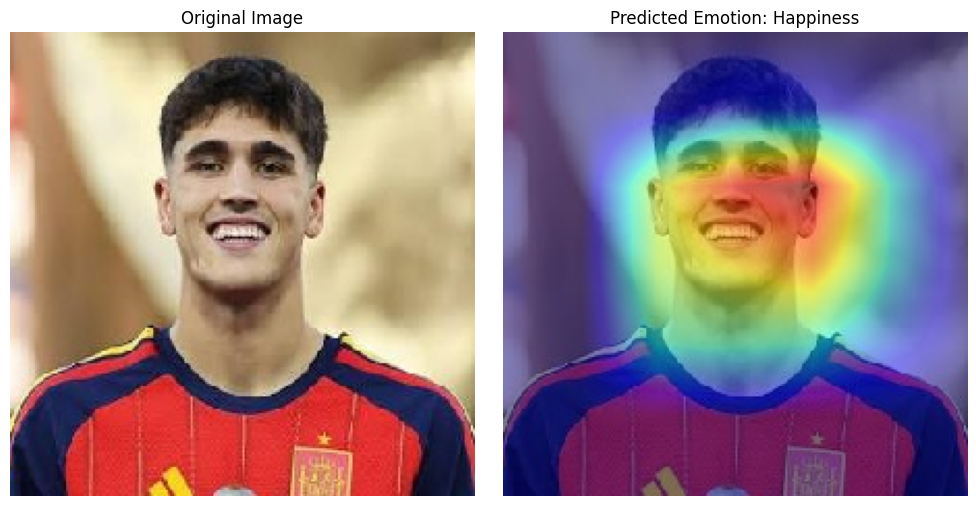

In [ ]:
from tf_keras_vis.gradcam import Gradcam  # Import GradCAM
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam = Gradcam(model, clone=False)  # Initialize GradCAM

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam(loss, image, penultimate_layer=layer_name)  # Get heatmap
    cam = normalize(cam)
    return cam

# Specify the folder containing images
image_folder = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/Football'  # Replace with your folder path

# Loop through each image in the folder
for filename in os.listdir(image_folder):
    if filename.endswith(('.jpg', '.jpeg', '.png')):  # Check for image file extensions
        img_path = os.path.join(image_folder, filename)

        # Load and preprocess the image
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)  # Assuming you have preprocess_input defined

        # Generate heatmap using GradCAM
        heatmap = grad_cam_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        # Display the original and heatmap overlaid images
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

In [ ]:
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os
import random

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Function to get random images
def get_random_images(emotion_path, num_images=3, random_state=None):
    """Returns a list of paths to random images from the given emotion path."""
    if random_state:
        random.seed(random_state)  # Set random seed for reproducibility
    image_files = os.listdir(emotion_path)
    random_images = random.sample(image_files, num_images)
    return [os.path.join(emotion_path, img) for img in random_images]

def grad_cam_plus_plus_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam_plus_plus = GradcamPlusPlus(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam_plus_plus(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam # Added indentation here

# Set random seed (you can change this to any integer)
random_state = 99

# Loop through each emotion category
for emotion in emotion_categories:
    print(f"Processing emotion: {emotion}")
    emotion_path = os.path.join('/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train', emotion)

    # Get random image paths using the function with random state
    img_paths = get_random_images(emotion_path, num_images=3, random_state=random_state)

     # Loop through 3 images for each emotion
    for i, img_path in enumerate(img_paths):
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)

        heatmap = grad_cam_plus_plus_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

In [ ]:
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os
import random

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

# Function to get random images
def get_random_images(emotion_path, num_images=3, random_state=None):
    """Returns a list of paths to random images from the given emotion path."""
    if random_state:
        random.seed(random_state)  # Set random seed for reproducibility
    image_files = os.listdir(emotion_path)
    random_images = random.sample(image_files, num_images)
    return [os.path.join(emotion_path, img) for img in random_images]

def grad_cam_plus_plus_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam_plus_plus = GradcamPlusPlus(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam_plus_plus(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam # Added indentation here

# Set random seed (you can change this to any integer)
random_state = 6

# Loop through each emotion category
for emotion in emotion_categories:
    print(f"Processing emotion: {emotion}")
    emotion_path = os.path.join('/content/drive/My Drive/Facial_Emotion_Recognition_Project/FER_25/Train', emotion)

    # Get random image paths using the function with random state
    img_paths = get_random_images(emotion_path, num_images=3, random_state=random_state)

     # Loop through 3 images for each emotion
    for i, img_path in enumerate(img_paths):
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)

        heatmap = grad_cam_plus_plus_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

gradCAM++ prediction for a single input

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


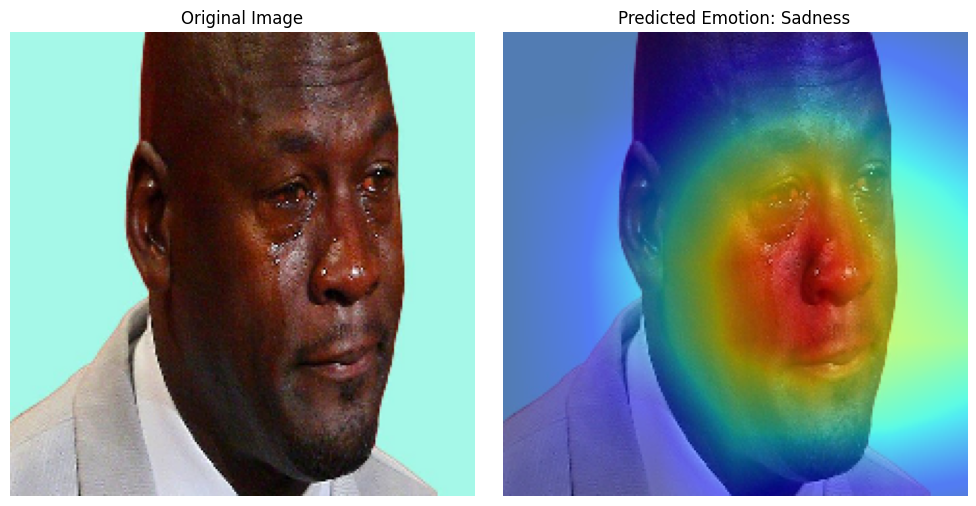

In [ ]:
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus  # Import GradCAM++
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_plus_plus_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam_plus_plus = GradcamPlusPlus(model, clone=False)  # Initialize GradCAM++

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam_plus_plus(loss, image, penultimate_layer=layer_name)  # Get heatmap
    cam = normalize(cam)
    return cam

# Load and preprocess the image
img_path = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/jordan.jpg'
img = image.load_img(img_path, target_size=(224, 224))
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = preprocess_input(x)  # Preprocess if needed

# Generate heatmap using GradCAM++
heatmap = grad_cam_plus_plus_heatmap(model, x)
heatmap = np.uint8(255 * heatmap[0])

# Display the original and heatmap overlaid images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Original Image
axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis('off')

# Heatmap Overlay (using GradCAM++ heatmap)
axes[1].imshow(img)
axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
axes[1].set_title(f"Predicted Emotion: {emotion_categories[np.argmax(model.predict(x))]}")
axes[1].axis('off')

plt.tight_layout()
plt.show()

gradCAM++ prediction for 3 input

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


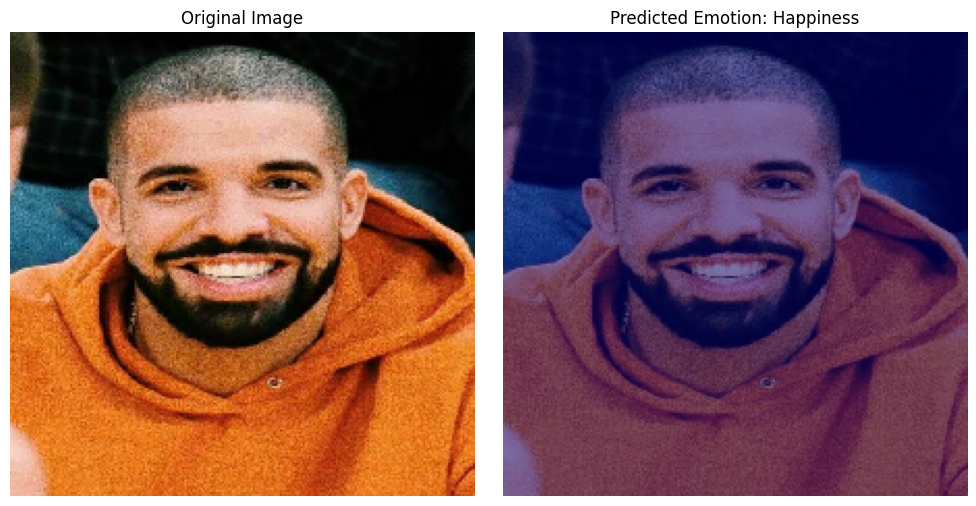

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


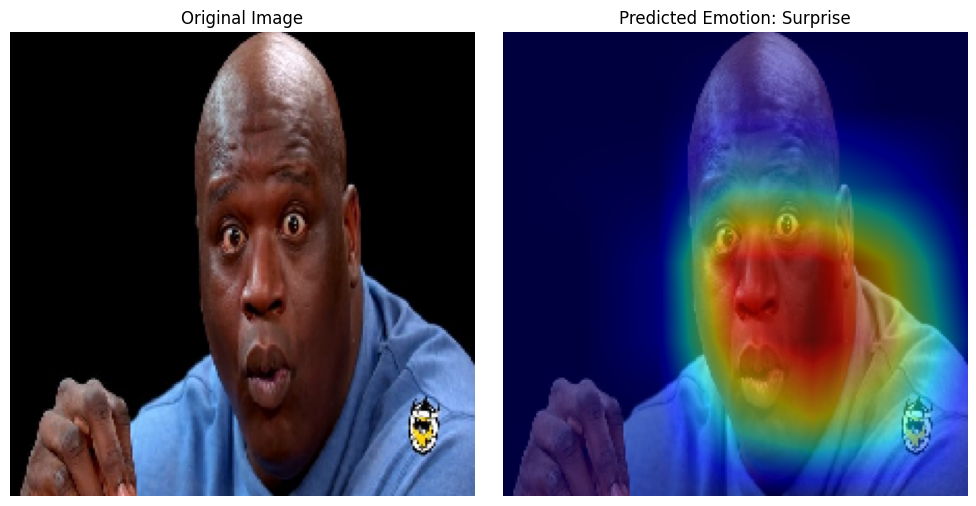

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


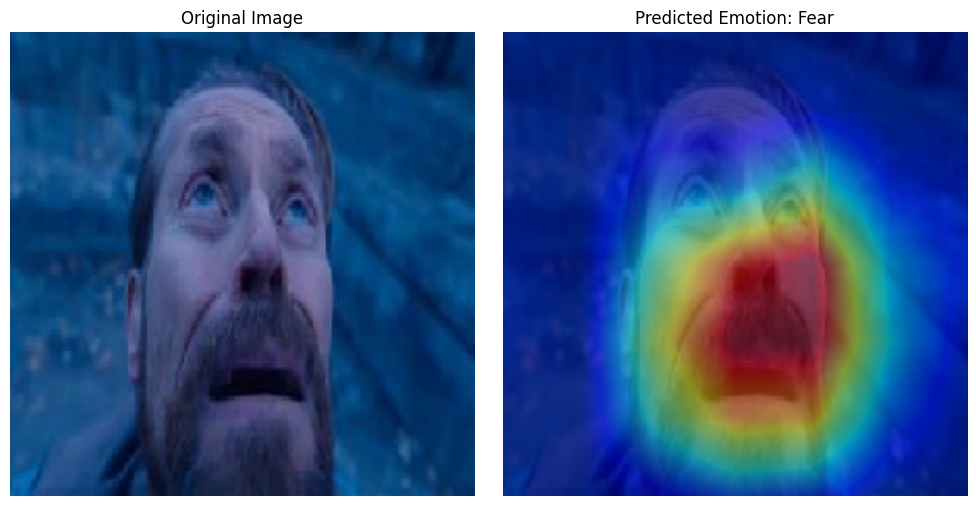

In [ ]:
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_plus_plus_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam_plus_plus = GradcamPlusPlus(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam_plus_plus(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam

# Load and preprocess 3 images
img_paths = [
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/drake.jpg',
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/shaq1.jpg',
    '/content/drive/My Drive/Facial_Emotion_Recognition_Project/dafoe.jpg'
]

# Process each image
for img_path in img_paths:
    img = image.load_img(img_path, target_size=(224, 224))
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)  # Assuming you have preprocess_input defined

    heatmap = grad_cam_plus_plus_heatmap(model, x)  # Call the GradCAM++ function
    heatmap = np.uint8(255 * heatmap[0])

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    axes[0].imshow(img)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(img)
    axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
    predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
    axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


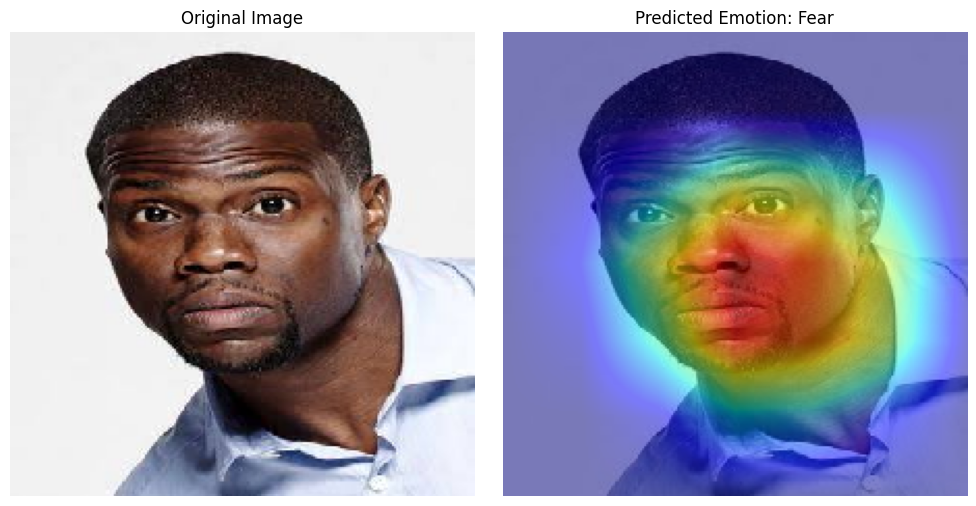

In [ ]:
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_plus_plus_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam_plus_plus = GradcamPlusPlus(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam_plus_plus(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam

# Specify the folder containing images
image_folder = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/celeb'  # Replace with your folder path

# Loop through each image in the folder
for filename in os.listdir(image_folder):
    if filename.endswith(('.jpg', '.jpeg', '.png')):  # Check for image file extensions
        img_path = os.path.join(image_folder, filename)

        # Load and preprocess the image
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)  # Assuming you have preprocess_input defined

        # Generate heatmap using GradCAM++
        heatmap = grad_cam_plus_plus_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        # Display the original and heatmap overlaid images
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step


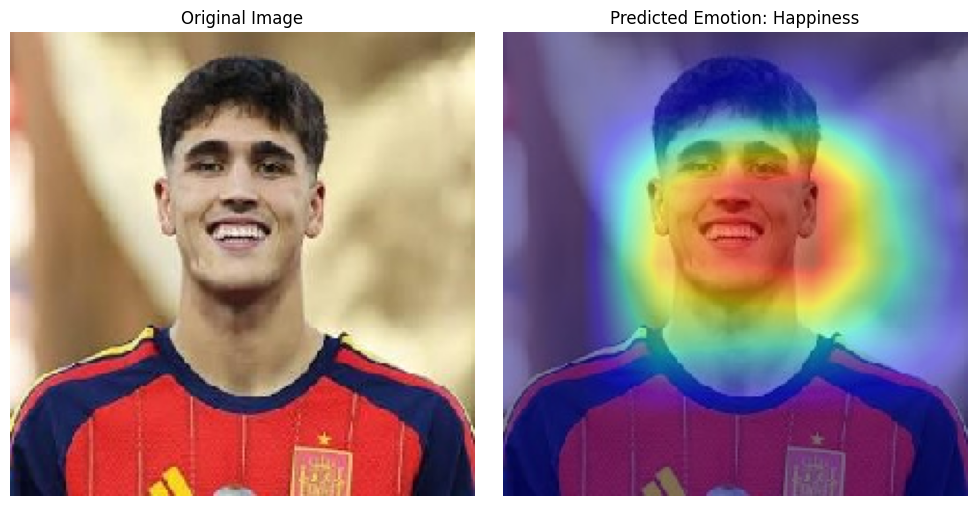

In [ ]:
from tf_keras_vis.gradcam_plus_plus import GradcamPlusPlus
from tf_keras_vis.utils import normalize
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import os

# Define emotion categories
emotion_categories = ['Anger', 'Disgust', 'Fear', 'Happiness', 'Neutral', 'Sadness', 'Surprise']

def grad_cam_plus_plus_heatmap(model, image, layer_name='conv5_block3_out'):
    gradcam_plus_plus = GradcamPlusPlus(model, clone=False)

    def loss(output):
        predicted_class = np.argmax(model.predict(image))
        return output[:, predicted_class]

    cam = gradcam_plus_plus(loss, image, penultimate_layer=layer_name)
    cam = normalize(cam)
    return cam

# Specify the folder containing images
image_folder = '/content/drive/My Drive/Facial_Emotion_Recognition_Project/Football'  # Replace with your folder path

# Loop through each image in the folder
for filename in os.listdir(image_folder):
    if filename.endswith(('.jpg', '.jpeg', '.png')):  # Check for image file extensions
        img_path = os.path.join(image_folder, filename)

        # Load and preprocess the image
        img = image.load_img(img_path, target_size=(224, 224))
        x = image.img_to_array(img)
        x = np.expand_dims(x, axis=0)
        x = preprocess_input(x)  # Assuming you have preprocess_input defined

        # Generate heatmap using GradCAM++
        heatmap = grad_cam_plus_plus_heatmap(model, x)
        heatmap = np.uint8(255 * heatmap[0])

        # Display the original and heatmap overlaid images
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))

        axes[0].imshow(img)
        axes[0].set_title("Original Image")
        axes[0].axis('off')

        axes[1].imshow(img)
        axes[1].imshow(heatmap, cmap='jet', alpha=0.5)
        predicted_emotion = emotion_categories[np.argmax(model.predict(x))]
        axes[1].set_title(f"Predicted Emotion: {predicted_emotion}")
        axes[1].axis('off')

        plt.tight_layout()
        plt.show()